<a href="https://colab.research.google.com/github/VasilisPapageorgiou/Bayesian-Embeddings/blob/main/Sim2_Bayesian_Embedding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# SIMULATION 2 — compact, theory-consistent, tuned-mixing version
# Same statistical model, priors, MCMC, DP, refitting, validation,
# diagnostics, checkpointing, and pilot/final settings as the full version.
# PILOT_MODE=True by default.

MODE = input('Simulation 2 MCMC-tuned: type 1 to START FROM THE BEGINNING or 2 to RESUME FROM THE LAST CHECKPOINT: ').strip()
if MODE not in {'1', '2'}:
    raise ValueError('Please rerun the cell and enter either 1 or 2.')
import os
import gc
import json
import time
import pickle
import random
import hashlib
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.special import betaln
import torch
import torch.nn as nn
import torch.nn.functional as F
warnings.filterwarnings('ignore')
DEVICE = torch.device('cpu')
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/JRSSB_Embedding_Allocation/Simulation2_full_theory_consistent_tuned'
except Exception:
    ROOT = './JRSSB_Embedding_Allocation/Simulation2_full_theory_consistent_tuned'
    print('Google Drive was not detected. Using local directory:', ROOT)
os.makedirs(ROOT, exist_ok=True)
CHECKPOINT_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_checkpoint.pkl')
RESULTS_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_replication_results.csv')
BUDGET_RESULTS_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_budget_results.csv')
DIMENSION_RESULTS_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_dimension_results.csv')
SUMMARY_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_summary.csv')
DIMENSION_SUMMARY_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_dimension_summary.csv')
DP_BENCHMARK_PATH = os.path.join(ROOT, 'simulation2_theory_consistent_tuned_DP_benchmark.csv')
PILOT_MODE = False
BASE_SEED = 314159
CHECKPOINT_SECONDS = 20 * 60
N_LEVELS = [3, 5, 8, 4, 10, 6, 7, 12, 5, 9, 4, 11]
M = len(N_LEVELS)
P_Z = 5
Q = 5
P_U = 3
K_LIST = [min(nj - 1, P_Z) for nj in N_LEVELS]
TARGET_DIMS = {'heterogeneous': (1, 4, 2, 1, 4, 2, 3, 1, 2, 4, 1, 3), 'near_homogeneous': (2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2)}
for regime, d0 in TARGET_DIMS.items():
    for j in range(M):
        if not 1 <= d0[j] <= K_LIST[j]:
            raise ValueError(f'Invalid target dimension for {regime}, predictor {j + 1}.')
REGIMES = ['heterogeneous', 'near_homogeneous']
N_TRAIN = 1200
N_VAL = 500
N_TEST = 4000
NOISE_SD = 0.1
ZETA_N = 0.0015
RANK_PRIOR = 'uniform'
SINGULAR_SHAPE = 2.0
SINGULAR_RATE = 1.0
RATIO_ALPHA = 1.0
RATIO_BETA = 1.0
TAU_GAMMA = 2.5
TAU_MU = 2.5
SIGMA_A0 = 2.5
SIGMA_B0 = 0.02
RED_HIDDEN = (P_Z,)
RED_WEIGHT_DECAY = 0.0005
if PILOT_MODE:
    N_REPS = 5
    REF_EPOCHS = 300
    RED_EPOCHS = 250
    REF_RESTARTS = 5
    RED_RESTARTS = 5
    MCMC_ITERS = 2500
    MCMC_BURN = 1250
    MCMC_THIN = 5
else:
    N_REPS = 50
    REF_EPOCHS = 400
    RED_EPOCHS = 300
    REF_RESTARTS = 5
    RED_RESTARTS = 5
    MCMC_ITERS = 3000
    MCMC_BURN = 1500
    MCMC_THIN = 5
MCMC_ADAPT_EVERY = 25
MCMC_ADAPT_FRACTION = 0.8
MCMC_TARGET_ORIENTATION = 0.3
MCMC_TARGET_SPECTRUM = 0.3
MCMC_TARGET_GAMMA = 0.25
MCMC_TARGET_MU = 0.3
AUXILIARY_INITIAL_BETA = 0.03
SPECTRUM_INITIAL_STEP = 0.08
RANK_MOVE_EVERY = 1
GAMMA_INITIAL_STEP = 0.01
MU_INITIAL_STEP = 0.01
MCMC_REFERENCE_N = 500.0
MCMC_ADAPT_GAIN = 0.7
AUXILIARY_BETA_MIN = 0.001
AUXILIARY_BETA_MAX = 0.3
SPECTRUM_STEP_MIN = 0.002
SPECTRUM_STEP_MAX = 0.3
GAMMA_STEP_MIN = 0.0005
GAMMA_STEP_MAX = 0.05
MU_STEP_MIN = 0.0005
MU_STEP_MAX = 0.05
INITIAL_RANK_ENERGY = 0.99
BIRTH_SMALL_WEIGHT = 0.80
BIRTH_SMALL_ALPHA = 1.0
BIRTH_SMALL_BETA = 8.0
BIRTH_PRIOR_WEIGHT = 0.20
MIN_COST = int(sum(N_LEVELS))
MAX_COST = int(sum((N_LEVELS[j] * K_LIST[j] for j in range(M))))
BUDGETS = [MIN_COST, 125, 170, 215, 255, 300, 340, MAX_COST]
BUDGETS = sorted(set(BUDGETS))
TRUE_TARGET_COST = {regime: int(sum((N_LEVELS[j] * TARGET_DIMS[regime][j] for j in range(M)))) for regime in REGIMES}
CONFIG_FOR_HASH = {'pilot': PILOT_MODE, 'n_reps': N_REPS, 'n_levels': N_LEVELS, 'p_z': P_Z, 'q': Q, 'p_u': P_U, 'target_dims': TARGET_DIMS, 'n_train': N_TRAIN, 'n_val': N_VAL, 'n_test': N_TEST, 'noise_sd': NOISE_SD, 'zeta_n': ZETA_N, 'budgets': BUDGETS, 'rank_prior': RANK_PRIOR, 'singular_shape': SINGULAR_SHAPE, 'singular_rate': SINGULAR_RATE, 'ratio_alpha': RATIO_ALPHA, 'ratio_beta': RATIO_BETA, 'tau_gamma': TAU_GAMMA, 'tau_mu': TAU_MU, 'sigma_a0': SIGMA_A0, 'sigma_b0': SIGMA_B0, 'red_hidden': RED_HIDDEN, 'red_weight_decay': RED_WEIGHT_DECAY, 'ref_epochs': REF_EPOCHS, 'red_epochs': RED_EPOCHS, 'ref_restarts': REF_RESTARTS, 'red_restarts': RED_RESTARTS, 'mcmc_iters': MCMC_ITERS, 'mcmc_burn': MCMC_BURN, 'mcmc_thin': MCMC_THIN, 'adapt_every': MCMC_ADAPT_EVERY, 'adapt_fraction': MCMC_ADAPT_FRACTION, 'target_orientation': MCMC_TARGET_ORIENTATION, 'target_spectrum': MCMC_TARGET_SPECTRUM, 'target_gamma': MCMC_TARGET_GAMMA, 'target_mu': MCMC_TARGET_MU, 'auxiliary_initial_beta': AUXILIARY_INITIAL_BETA, 'spectrum_initial_step': SPECTRUM_INITIAL_STEP, 'rank_move_every': RANK_MOVE_EVERY, 'gamma_initial_step': GAMMA_INITIAL_STEP, 'mu_initial_step': MU_INITIAL_STEP, 'mcmc_reference_n': MCMC_REFERENCE_N, 'adapt_gain': MCMC_ADAPT_GAIN, 'initial_rank_energy': INITIAL_RANK_ENERGY, 'birth_small_weight': BIRTH_SMALL_WEIGHT, 'birth_small_alpha': BIRTH_SMALL_ALPHA, 'birth_small_beta': BIRTH_SMALL_BETA, 'birth_prior_weight': BIRTH_PRIOR_WEIGHT}
CONFIG_SIGNATURE = hashlib.md5(json.dumps(CONFIG_FOR_HASH, sort_keys=True).encode()).hexdigest()

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def random_orthogonal(d, rng):
    A = rng.normal(size=(d, d))
    Qm, R = np.linalg.qr(A)
    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1.0
    Qm = Qm * signs
    return Qm

def centered_orthonormal_matrix(n, k, rng):
    A = rng.normal(size=(n, k))
    A -= A.mean(axis=0, keepdims=True)
    Qm, _ = np.linalg.qr(A)
    Qm -= Qm.mean(axis=0, keepdims=True)
    Qm, _ = np.linalg.qr(Qm)
    return Qm[:, :k]

def make_true_spectrum(predictor_index, target_dimension):
    """
    Construct a rank-target_dimension spectrum.

    Strong directions remain clearly separated from zero.

    Scaling by sqrt(N_j) keeps the typical row-level effect
    comparable across predictors with different numbers
    of categories.
    """
    Kj = K_LIST[predictor_index]
    Nj = N_LEVELS[predictor_index]
    strong_template = np.array([1.35, 1.1, 0.85, 0.6, 0.45], dtype=float)
    median_n = float(np.median(N_LEVELS))
    cardinality_scale = np.sqrt(Nj / median_n)
    predictor_scale = 1.0 + 0.015 * (predictor_index - (M - 1) / 2)
    scale = cardinality_scale * predictor_scale
    s = np.zeros(Kj, dtype=float)
    s[:target_dimension] = strong_template[:target_dimension] * scale
    return s

def get_spectra(regime):
    d0 = TARGET_DIMS[regime]
    return [make_true_spectrum(j, d0[j]) for j in range(M)]

def complexity_label(d):
    if d == 1:
        return 'rank_1'
    if d == 2:
        return 'rank_2'
    if d == 3:
        return 'rank_3'
    return 'rank_4'

def make_theta_from_singular_values(n, pz, singular_values, rng):
    k = min(n - 1, pz)
    U = centered_orthonormal_matrix(n, k, rng)
    V = random_orthogonal(pz, rng)[:, :k]
    s = np.asarray(singular_values[:k], dtype=float)
    theta = U @ np.diag(s) @ V.T
    theta -= theta.mean(axis=0, keepdims=True)
    return theta

def make_teacher_weights(seed=90210):
    rng = np.random.default_rng(seed)
    W1 = random_orthogonal(P_Z, rng)
    W2 = random_orthogonal(P_Z, rng)
    b1 = np.array([0.1, -0.05, 0.05, -0.1, 0.05], dtype=float)
    b2 = np.array([0.05, -0.05, 0.05, 0.0, -0.05], dtype=float)
    return [(W1, b1), (W2, b2)]
TEACHER_WEIGHTS = make_teacher_weights()

def mlp_forward_numpy(z, weights):
    W1, b1 = weights[0]
    W2, b2 = weights[1]
    hidden = np.tanh(z @ W1.T + b1)
    return hidden @ W2.T + b2

def build_true_parameters(regime):
    rng = np.random.default_rng(4567)
    spectra = get_spectra(regime)
    target_dims = TARGET_DIMS[regime]
    theta = [make_theta_from_singular_values(N_LEVELS[j], P_Z, spectra[j], rng) for j in range(M)]
    gamma = rng.normal(scale=0.15, size=(P_U, P_Z))
    mu = np.array([0.1, -0.05, 0.05, 0.05, -0.05], dtype=float)
    labels = [complexity_label(d) for d in target_dims]
    return {'theta': theta, 'gamma': gamma, 'mu': mu, 'spectra': spectra, 'target_dims': tuple(target_dims), 'labels': labels}

def generate_dataset(n, true_par, noise_sd, seed):
    rng = np.random.default_rng(seed)
    C = [rng.integers(0, N_LEVELS[j], size=n) for j in range(M)]
    U = rng.normal(size=(n, P_U))
    z = np.tile(true_par['mu'], (n, 1))
    z += U @ true_par['gamma']
    for j in range(M):
        z += true_par['theta'][j][C[j], :]
    mean = mlp_forward_numpy(z, TEACHER_WEIGHTS)
    y = mean + noise_sd * rng.normal(size=mean.shape)
    return (C, U, y)

class ReferenceModel(nn.Module):

    def __init__(self, seed=0):
        super().__init__()
        set_seed(seed)
        self.embeddings = nn.ModuleList([nn.Embedding(N_LEVELS[j], P_Z) for j in range(M)])
        for emb in self.embeddings:
            nn.init.normal_(emb.weight, std=0.05)
        self.gamma = nn.Parameter(0.05 * torch.randn(P_U, P_Z))
        self.mu = nn.Parameter(torch.zeros(P_Z))
        self.lin1 = nn.Linear(P_Z, P_Z)
        self.lin2 = nn.Linear(P_Z, Q)
        with torch.no_grad():
            q1, _ = torch.linalg.qr(torch.randn(P_Z, P_Z))
            q2, _ = torch.linalg.qr(torch.randn(P_Z, P_Z))
            self.lin1.weight.copy_(q1)
            self.lin2.weight.copy_(q2)
            self.lin1.bias.zero_()
            self.lin2.bias.zero_()

    def latent(self, C, U):
        z = self.mu.unsqueeze(0) + U @ self.gamma
        for j in range(M):
            z = z + self.embeddings[j](C[j])
        return z

    def phi(self, z):
        return self.lin2(torch.tanh(self.lin1(z)))

    def forward(self, C, U):
        return self.phi(self.latent(C, U))

    @torch.no_grad()
    def center_embeddings_(self):
        for emb in self.embeddings:
            emb.weight -= emb.weight.mean(dim=0, keepdim=True)

    @torch.no_grad()
    def project_mlp_orthogonal_(self):
        for layer in [self.lin1, self.lin2]:
            U_svd, _, Vh = torch.linalg.svd(layer.weight, full_matrices=False)
            layer.weight.copy_(U_svd @ Vh)

def train_reference_once(C, U, y, seed, heartbeat=None):
    set_seed(seed)
    model = ReferenceModel(seed=seed).to(DEVICE)
    C_t = [torch.tensor(x, dtype=torch.long, device=DEVICE) for x in C]
    U_t = torch.tensor(U, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y, dtype=torch.float32, device=DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-05)
    for epoch in range(REF_EPOCHS):
        optimizer.zero_grad()
        pred = model(C_t, U_t)
        loss = F.mse_loss(pred, y_t)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        model.center_embeddings_()
        model.project_mlp_orthogonal_()
        if heartbeat is not None and (epoch + 1) % 50 == 0:
            heartbeat()
    with torch.no_grad():
        train_loss = float(F.mse_loss(model(C_t, U_t), y_t).cpu())
    return (model, train_loss)

def train_reference_model(C, U, y, seed, heartbeat=None):
    best_model = None
    best_loss = np.inf
    for r in range(REF_RESTARTS):
        model, loss = train_reference_once(C, U, y, seed + 1000 * r, heartbeat)
        if loss < best_loss:
            if best_model is not None:
                del best_model
            best_model = model
            best_loss = loss
        else:
            del model
        gc.collect()
    return (best_model, best_loss)

@torch.no_grad()
def predict_reference(model, C, U):
    C_t = [torch.tensor(x, dtype=torch.long, device=DEVICE) for x in C]
    U_t = torch.tensor(U, dtype=torch.float32, device=DEVICE)
    return model(C_t, U_t).cpu().numpy()

def extract_reference_parameters(model):
    theta = [emb.weight.detach().cpu().numpy().astype(float).copy() for emb in model.embeddings]
    theta = [x - x.mean(axis=0, keepdims=True) for x in theta]
    gamma = model.gamma.detach().cpu().numpy().astype(float).copy()
    mu = model.mu.detach().cpu().numpy().astype(float).copy()
    W1 = model.lin1.weight.detach().cpu().numpy().astype(float).copy()
    b1 = model.lin1.bias.detach().cpu().numpy().astype(float).copy()
    W2 = model.lin2.weight.detach().cpu().numpy().astype(float).copy()
    b2 = model.lin2.bias.detach().cpu().numpy().astype(float).copy()
    weights = [(W1, b1), (W2, b2)]
    return (theta, gamma, mu, weights)

def centered_basis(n):
    pi = np.full(n, 1.0 / n, dtype=float)
    _, _, vh = np.linalg.svd(pi.reshape(1, -1), full_matrices=True)
    return vh[1:, :].T.copy()
CENTER_BASES = [centered_basis(nj) for nj in N_LEVELS]

def stable_sigmoid(x):
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x, dtype=float)
    positive = x >= 0
    out[positive] = 1.0 / (1.0 + np.exp(-x[positive]))
    exp_x = np.exp(x[~positive])
    out[~positive] = exp_x / (1.0 + exp_x)
    return out

def logit(p):
    p = np.clip(p, 1e-10, 1.0 - 1e-10)
    return np.log(p) - np.log1p(-p)

def rank_prior_probability(j, rank):
    Kj = K_LIST[j]
    if rank < 0 or rank > Kj:
        return 0.0
    return 1.0 / float(Kj + 1)

def spectral_s2_from_state(state):
    rank = int(state['rank'])
    if rank == 0:
        return np.zeros(0, dtype=float)
    s2 = np.empty(rank, dtype=float)
    s2[0] = np.exp(state['log_s1_sq'])
    if rank > 1:
        rho = stable_sigmoid(state['eta'])
        for k in range(1, rank):
            s2[k] = rho[k - 1] * s2[k - 1]
    return s2

def qr_orthonormal(X):
    X = np.asarray(X, dtype=float)
    if X.shape[1] == 0:
        return np.zeros_like(X)
    Qm, Rm = np.linalg.qr(X, mode='reduced')
    diag = np.diag(Rm)
    signs = np.sign(diag)
    signs[signs == 0] = 1.0
    Qm = Qm * signs
    return Qm[:, :X.shape[1]]

def state_orientations(state, j):
    rank = int(state['rank'])
    if rank == 0:
        return (np.zeros((N_LEVELS[j], 0), dtype=float), np.zeros((P_Z, 0), dtype=float))
    Q_u = qr_orthonormal(state['A'])
    Q_v = qr_orthonormal(state['B'])
    U = CENTER_BASES[j] @ Q_u
    V = Q_v
    return (U, V)

def state_to_theta(state, j):
    rank = int(state['rank'])
    if rank == 0:
        return np.zeros((N_LEVELS[j], P_Z), dtype=float)
    U, V = state_orientations(state, j)
    s = np.sqrt(spectral_s2_from_state(state))
    theta = U @ np.diag(s) @ V.T
    theta -= theta.mean(axis=0, keepdims=True)
    return theta

def initialize_rank_spectral_state(theta, j):
    """Initialize rank from the fitted reference spectrum; this affects only the chain start."""
    theta = theta - theta.mean(axis=0, keepdims=True)
    U, s, Vt = np.linalg.svd(theta, full_matrices=False)
    K = K_LIST[j]
    s = s[:K]
    energy = s ** 2
    total = float(np.sum(energy))
    if total <= 1e-14:
        return {'rank': 0, 'A': np.zeros((N_LEVELS[j] - 1, 0), dtype=float), 'B': np.zeros((P_Z, 0), dtype=float), 'log_s1_sq': None, 'eta': np.zeros(0, dtype=float)}
    cumulative = np.cumsum(energy) / total
    rank = int(np.searchsorted(cumulative, INITIAL_RANK_ENERGY) + 1)
    rank = max(1, min(rank, K))
    U_r = U[:, :rank]
    V_r = Vt.T[:, :rank]
    Q_u = qr_orthonormal(CENTER_BASES[j].T @ U_r)
    V_r = qr_orthonormal(V_r)
    A = Q_u.copy()
    B = V_r.copy()
    s2 = np.maximum(s[:rank] ** 2, 1e-10)
    s2 = np.minimum.accumulate(s2)
    eta = np.zeros(max(rank - 1, 0), dtype=float)
    if rank > 1:
        rho = np.clip(s2[1:] / s2[:-1], 1e-08, 1.0 - 1e-08)
        eta = logit(rho)
    return {'rank': rank, 'A': A, 'B': B, 'log_s1_sq': float(np.log(s2[0])), 'eta': eta.copy()}

def log_spectral_prior_transformed(state):
    rank = int(state['rank'])
    if rank == 0:
        return 0.0
    x = float(state['log_s1_sq'])
    out = SINGULAR_SHAPE * x - SINGULAR_RATE * np.exp(x)
    if rank > 1:
        rho = np.clip(stable_sigmoid(state['eta']), 1e-12, 1.0 - 1e-12)
        out += float(np.sum(RATIO_ALPHA * np.log(rho) + RATIO_BETA * np.log1p(-rho)))
    return float(out)

def pcn_gaussian_proposal(X, beta, rng):
    if X.size == 0:
        return X.copy()
    beta = float(np.clip(beta, 0.0, 0.999999))
    return np.sqrt(1.0 - beta ** 2) * X + beta * rng.normal(size=X.shape)

def propose_local_rank_spectral_state(state, auxiliary_beta, spectrum_step, rng):
    rank = int(state['rank'])
    proposal = {'rank': rank, 'A': state['A'].copy(), 'B': state['B'].copy(), 'log_s1_sq': state['log_s1_sq'], 'eta': state['eta'].copy()}
    if rank == 0:
        return proposal
    proposal['A'] = pcn_gaussian_proposal(state['A'], auxiliary_beta, rng)
    proposal['B'] = pcn_gaussian_proposal(state['B'], auxiliary_beta, rng)
    proposal['log_s1_sq'] = float(state['log_s1_sq'] + spectrum_step * rng.normal())
    if rank > 1:
        proposal['eta'] = state['eta'] + spectrum_step * rng.normal(size=rank - 1)
    return proposal

def propose_orientation_state(state, auxiliary_beta, update_A, rng):
    """Column-wise pCN update; reversible with respect to the iid N(0,1) auxiliary prior."""
    rank = int(state['rank'])
    proposal = {'rank': rank, 'A': state['A'].copy(), 'B': state['B'].copy(), 'log_s1_sq': state['log_s1_sq'], 'eta': state['eta'].copy()}
    if rank == 0:
        return proposal
    key = 'A' if update_A else 'B'
    col = int(rng.integers(0, rank))
    x = state[key][:, col]
    beta = float(np.clip(auxiliary_beta, 0.0, 0.999999))
    proposal[key][:, col] = np.sqrt(1.0 - beta ** 2) * x + beta * rng.normal(size=x.shape)
    return proposal

def propose_spectrum_coordinate_state(state, spectrum_step, rng):
    """Random-scan update of one transformed spectral coordinate."""
    rank = int(state['rank'])
    proposal = {'rank': rank, 'A': state['A'].copy(), 'B': state['B'].copy(), 'log_s1_sq': state['log_s1_sq'], 'eta': state['eta'].copy()}
    if rank == 0:
        return proposal
    coordinate = int(rng.integers(0, rank))
    if coordinate == 0:
        proposal['log_s1_sq'] = float(state['log_s1_sq'] + spectrum_step * rng.normal())
    else:
        proposal['eta'][coordinate - 1] += spectrum_step * rng.normal()
    return proposal

def effective_sample_size(x):
    """Simple positive-sequence ESS diagnostic for a one-dimensional chain."""
    x = np.asarray(x, dtype=float)
    n = int(x.size)
    if n < 4:
        return float(n)
    x = x - np.mean(x)
    var = float(np.dot(x, x) / n)
    if not np.isfinite(var) or var <= 1e-16:
        return float(n)
    rho_sum = 0.0
    for lag in range(1, n):
        acov = float(np.dot(x[:-lag], x[lag:]) / (n - lag))
        rho = acov / var
        if not np.isfinite(rho) or rho <= 0.0:
            break
        rho_sum += rho
    return float(max(1.0, min(float(n), n / (1.0 + 2.0 * rho_sum))))

def log_beta_density(x, a, b):
    x = float(np.clip(x, 1e-12, 1.0 - 1e-12))
    return float((a - 1.0) * np.log(x) + (b - 1.0) * np.log1p(-x) - betaln(a, b))

def sample_birth_rho(rng):
    if rng.uniform() < BIRTH_SMALL_WEIGHT:
        return float(rng.beta(BIRTH_SMALL_ALPHA, BIRTH_SMALL_BETA))
    return float(rng.beta(RATIO_ALPHA, RATIO_BETA))

def log_birth_rho_density(rho):
    log_small = np.log(BIRTH_SMALL_WEIGHT) + log_beta_density(rho, BIRTH_SMALL_ALPHA, BIRTH_SMALL_BETA)
    log_prior_component = np.log(BIRTH_PRIOR_WEIGHT) + log_beta_density(rho, RATIO_ALPHA, RATIO_BETA)
    return float(np.logaddexp(log_small, log_prior_component))

def log_prior_rho_density(rho):
    return log_beta_density(rho, RATIO_ALPHA, RATIO_BETA)

def birth_death_probabilities(rank, K):
    if rank == 0:
        return (1.0, 0.0)
    if rank == K:
        return (0.0, 1.0)
    return (0.5, 0.5)

def propose_rank_move(state, j, rng):
    """Adjacent reversible-jump rank move with exact proposal correction."""
    rank = int(state['rank'])
    K = K_LIST[j]
    p_birth, p_death = birth_death_probabilities(rank, K)
    do_birth = rng.uniform() < p_birth if p_birth > 0 and p_death > 0 else p_birth > 0
    if do_birth:
        new_rank = rank + 1
        A = np.column_stack([state['A'], rng.normal(size=(N_LEVELS[j] - 1, 1))])
        B = np.column_stack([state['B'], rng.normal(size=(P_Z, 1))])
        rho_correction = 0.0
        if rank == 0:
            s1_sq = rng.gamma(shape=SINGULAR_SHAPE, scale=1.0 / SINGULAR_RATE)
            log_s1_sq = float(np.log(max(s1_sq, 1e-12)))
            eta = np.zeros(0, dtype=float)
        else:
            rho_new = sample_birth_rho(rng)
            log_s1_sq = state['log_s1_sq']
            eta = np.concatenate([state['eta'], np.array([logit(rho_new)], dtype=float)])
            rho_correction = log_prior_rho_density(rho_new) - log_birth_rho_density(rho_new)
        proposal = {'rank': new_rank, 'A': A, 'B': B, 'log_s1_sq': log_s1_sq, 'eta': eta}
        _, reverse_death = birth_death_probabilities(new_rank, K)
        log_hastings = (np.log(rank_prior_probability(j, new_rank)) - np.log(rank_prior_probability(j, rank)) + np.log(reverse_death) - np.log(p_birth) + rho_correction)
    else:
        new_rank = rank - 1
        rho_correction = 0.0
        if rank > 1:
            rho_removed = float(stable_sigmoid(np.array([state['eta'][-1]]))[0])
            rho_correction = log_birth_rho_density(rho_removed) - log_prior_rho_density(rho_removed)
        if new_rank == 0:
            proposal = {'rank': 0, 'A': np.zeros((N_LEVELS[j] - 1, 0), dtype=float), 'B': np.zeros((P_Z, 0), dtype=float), 'log_s1_sq': None, 'eta': np.zeros(0, dtype=float)}
        else:
            proposal = {'rank': new_rank, 'A': state['A'][:, :new_rank].copy(), 'B': state['B'][:, :new_rank].copy(), 'log_s1_sq': state['log_s1_sq'], 'eta': state['eta'][:max(new_rank - 1, 0)].copy()}
        reverse_birth, _ = birth_death_probabilities(new_rank, K)
        log_hastings = (np.log(rank_prior_probability(j, new_rank)) - np.log(rank_prior_probability(j, rank)) + np.log(reverse_birth) - np.log(p_death) + rho_correction)
    return proposal, float(log_hastings)

def log_gamma_prior(gamma):
    return float(-0.5 * np.sum(gamma ** 2) / TAU_GAMMA ** 2)

def log_mu_prior(mu):
    return float(-0.5 * np.sum(mu ** 2) / TAU_MU ** 2)

def gaussian_loglik(y, yhat, sigma2):
    residual = y - yhat
    return float(-0.5 * y.size * np.log(2.0 * np.pi * sigma2) - 0.5 * np.sum(residual ** 2) / sigma2)

def latent_numpy(C, U, theta, gamma, mu):
    n = len(C[0])
    z = np.tile(mu, (n, 1))
    z += U @ gamma
    for j in range(M):
        z += theta[j][C[j], :]
    return z

def blocked_mcmc(C, U, y, theta_init, gamma_init, mu_init, fixed_mlp_weights, sigma2_init, seed, theta_true=None, heartbeat=None):
    rng = np.random.default_rng(seed)
    states = [initialize_rank_spectral_state(theta_init[j], j) for j in range(M)]
    theta = [state_to_theta(states[j], j) for j in range(M)]
    gamma = gamma_init.copy()
    mu = mu_init.copy()
    sigma2 = float(max(sigma2_init, 1e-06))
    z_cur = latent_numpy(C, U, theta, gamma, mu)
    yhat_cur = mlp_forward_numpy(z_cur, fixed_mlp_weights)
    ll_cur = gaussian_loglik(y, yhat_cur, sigma2)
    spectral_prior_cur = [log_spectral_prior_transformed(states[j]) for j in range(M)]
    gamma_prior_cur = log_gamma_prior(gamma)
    mu_prior_cur = log_mu_prior(mu)
    n_obs = len(C[0])
    n_scale = np.sqrt(MCMC_REFERENCE_N / float(n_obs))
    auxiliary_betas = np.full(M, AUXILIARY_INITIAL_BETA, dtype=float)
    spectrum_steps = np.full(M, SPECTRUM_INITIAL_STEP, dtype=float)
    gamma_step = float(GAMMA_INITIAL_STEP * n_scale)
    mu_step = float(MU_INITIAL_STEP * n_scale)
    orientation_window_accept = np.zeros(M)
    orientation_window_trials = np.zeros(M)
    spectrum_window_accept = np.zeros(M)
    spectrum_window_trials = np.zeros(M)
    gamma_window_accept = 0
    gamma_window_trials = 0
    mu_window_accept = 0
    mu_window_trials = 0
    orientation_post_accept = np.zeros(M)
    orientation_post_trials = np.zeros(M)
    spectrum_post_accept = np.zeros(M)
    spectrum_post_trials = np.zeros(M)
    rank_post_accept = np.zeros(M)
    rank_post_trials = np.zeros(M)
    gamma_post_accept = 0
    gamma_post_trials = 0
    mu_post_accept = 0
    mu_post_trials = 0
    singular_draws = [[] for _ in range(M)]
    rank_draws = [[] for _ in range(M)]
    sigma_draws = []
    theta_error_draws = []
    adapt_stop = int(MCMC_ADAPT_FRACTION * MCMC_BURN)
    adaptation_round = 0

    def evaluate_theta_proposal(j, proposal_state):
        theta_prop = state_to_theta(proposal_state, j)
        delta_latent = theta_prop[C[j], :] - theta[j][C[j], :]
        z_prop = z_cur + delta_latent
        yhat_prop = mlp_forward_numpy(z_prop, fixed_mlp_weights)
        ll_prop = gaussian_loglik(y, yhat_prop, sigma2)
        return (theta_prop, z_prop, yhat_prop, ll_prop)
    for it in range(MCMC_ITERS):
        for j in range(M):
            current_rank = int(states[j]['rank'])
            if current_rank > 0:
                proposal_state = propose_orientation_state(states[j], auxiliary_betas[j], update_A=(it + j) % 2 == 0, rng=rng)
                theta_prop, z_prop, yhat_prop, ll_prop = evaluate_theta_proposal(j, proposal_state)
                log_ratio = ll_prop - ll_cur
                accepted = np.log(rng.uniform()) < log_ratio
                if it < adapt_stop:
                    orientation_window_trials[j] += 1
                if it >= MCMC_BURN:
                    orientation_post_trials[j] += 1
                if accepted:
                    states[j] = proposal_state
                    theta[j] = theta_prop
                    z_cur = z_prop
                    yhat_cur = yhat_prop
                    ll_cur = ll_prop
                    if it < adapt_stop:
                        orientation_window_accept[j] += 1
                    if it >= MCMC_BURN:
                        orientation_post_accept[j] += 1
                proposal_state = propose_spectrum_coordinate_state(states[j], spectrum_steps[j], rng)
                theta_prop, z_prop, yhat_prop, ll_prop = evaluate_theta_proposal(j, proposal_state)
                spectral_prior_prop = log_spectral_prior_transformed(proposal_state)
                log_ratio = ll_prop + spectral_prior_prop - ll_cur - spectral_prior_cur[j]
                accepted = np.log(rng.uniform()) < log_ratio
                if it < adapt_stop:
                    spectrum_window_trials[j] += 1
                if it >= MCMC_BURN:
                    spectrum_post_trials[j] += 1
                if accepted:
                    states[j] = proposal_state
                    theta[j] = theta_prop
                    z_cur = z_prop
                    yhat_cur = yhat_prop
                    ll_cur = ll_prop
                    spectral_prior_cur[j] = spectral_prior_prop
                    if it < adapt_stop:
                        spectrum_window_accept[j] += 1
                    if it >= MCMC_BURN:
                        spectrum_post_accept[j] += 1
            if (it + 1) % RANK_MOVE_EVERY == 0:
                proposal_state, log_hastings = propose_rank_move(states[j], j, rng)
                theta_prop, z_prop, yhat_prop, ll_prop = evaluate_theta_proposal(j, proposal_state)
                log_ratio = ll_prop - ll_cur + log_hastings
                rank_accepted = np.log(rng.uniform()) < log_ratio
                if it >= MCMC_BURN:
                    rank_post_trials[j] += 1
                if rank_accepted:
                    states[j] = proposal_state
                    theta[j] = theta_prop
                    z_cur = z_prop
                    yhat_cur = yhat_prop
                    ll_cur = ll_prop
                    spectral_prior_cur[j] = log_spectral_prior_transformed(proposal_state)
                    if it >= MCMC_BURN:
                        rank_post_accept[j] += 1
        gamma_prop = gamma + gamma_step * rng.normal(size=gamma.shape)
        z_prop = z_cur + U @ (gamma_prop - gamma)
        yhat_prop = mlp_forward_numpy(z_prop, fixed_mlp_weights)
        ll_prop = gaussian_loglik(y, yhat_prop, sigma2)
        gamma_prior_prop = log_gamma_prior(gamma_prop)
        log_ratio = ll_prop + gamma_prior_prop - ll_cur - gamma_prior_cur
        gamma_accepted = np.log(rng.uniform()) < log_ratio
        if it < adapt_stop:
            gamma_window_trials += 1
        if it >= MCMC_BURN:
            gamma_post_trials += 1
        if gamma_accepted:
            gamma = gamma_prop
            z_cur = z_prop
            yhat_cur = yhat_prop
            ll_cur = ll_prop
            gamma_prior_cur = gamma_prior_prop
            if it < adapt_stop:
                gamma_window_accept += 1
            if it >= MCMC_BURN:
                gamma_post_accept += 1
        mu_prop = mu + mu_step * rng.normal(size=mu.shape)
        z_prop = z_cur + (mu_prop - mu)
        yhat_prop = mlp_forward_numpy(z_prop, fixed_mlp_weights)
        ll_prop = gaussian_loglik(y, yhat_prop, sigma2)
        mu_prior_prop = log_mu_prior(mu_prop)
        log_ratio = ll_prop + mu_prior_prop - ll_cur - mu_prior_cur
        mu_accepted = np.log(rng.uniform()) < log_ratio
        if it < adapt_stop:
            mu_window_trials += 1
        if it >= MCMC_BURN:
            mu_post_trials += 1
        if mu_accepted:
            mu = mu_prop
            z_cur = z_prop
            yhat_cur = yhat_prop
            ll_cur = ll_prop
            mu_prior_cur = mu_prior_prop
            if it < adapt_stop:
                mu_window_accept += 1
            if it >= MCMC_BURN:
                mu_post_accept += 1
        residual = y - yhat_cur
        shape_post = SIGMA_A0 + 0.5 * y.size
        rate_post = SIGMA_B0 + 0.5 * np.sum(residual ** 2)
        sigma2 = 1.0 / rng.gamma(shape=shape_post, scale=1.0 / rate_post)
        ll_cur = gaussian_loglik(y, yhat_cur, sigma2)
        if it < adapt_stop and (it + 1) % MCMC_ADAPT_EVERY == 0:
            adaptation_round += 1
            adaptive_gain = MCMC_ADAPT_GAIN / np.sqrt(adaptation_round)
            for j in range(M):
                if orientation_window_trials[j] > 0:
                    orientation_rate = orientation_window_accept[j] / orientation_window_trials[j]
                    auxiliary_betas[j] = float(np.clip(auxiliary_betas[j] * np.exp(adaptive_gain * (orientation_rate - MCMC_TARGET_ORIENTATION)), AUXILIARY_BETA_MIN, AUXILIARY_BETA_MAX))
                if spectrum_window_trials[j] > 0:
                    spectrum_rate = spectrum_window_accept[j] / spectrum_window_trials[j]
                    spectrum_steps[j] = float(np.clip(spectrum_steps[j] * np.exp(adaptive_gain * (spectrum_rate - MCMC_TARGET_SPECTRUM)), SPECTRUM_STEP_MIN, SPECTRUM_STEP_MAX))
            if gamma_window_trials > 0:
                gamma_rate = gamma_window_accept / gamma_window_trials
                gamma_step = float(np.clip(gamma_step * np.exp(adaptive_gain * (gamma_rate - MCMC_TARGET_GAMMA)), GAMMA_STEP_MIN, GAMMA_STEP_MAX))
            if mu_window_trials > 0:
                mu_rate = mu_window_accept / mu_window_trials
                mu_step = float(np.clip(mu_step * np.exp(adaptive_gain * (mu_rate - MCMC_TARGET_MU)), MU_STEP_MIN, MU_STEP_MAX))
            orientation_window_accept[:] = 0
            orientation_window_trials[:] = 0
            spectrum_window_accept[:] = 0
            spectrum_window_trials[:] = 0
            gamma_window_accept = 0
            gamma_window_trials = 0
            mu_window_accept = 0
            mu_window_trials = 0
        if it >= MCMC_BURN and (it - MCMC_BURN) % MCMC_THIN == 0:
            current_theta_error = 0.0
            for j in range(M):
                rank = int(states[j]['rank'])
                s = np.zeros(K_LIST[j], dtype=float)
                if rank > 0:
                    s[:rank] = np.sqrt(spectral_s2_from_state(states[j]))
                singular_draws[j].append(s)
                rank_draws[j].append(rank)
                if theta_true is not None:
                    current_theta_error += float(np.sum((theta[j] - theta_true[j]) ** 2))
            if theta_true is not None:
                theta_error_draws.append(current_theta_error)
            sigma_draws.append(sigma2)
        if heartbeat is not None and (it + 1) % 50 == 0:
            heartbeat()
    singular_draws = [np.asarray(x, dtype=float) for x in singular_draws]
    rank_draws = [np.asarray(x, dtype=int) for x in rank_draws]
    if any((len(x) == 0 for x in singular_draws)):
        raise RuntimeError('No posterior singular-value draws were retained.')
    mean_s2 = [np.mean(x ** 2, axis=0) for x in singular_draws]
    posterior_mean_rank = np.array([np.mean(x) for x in rank_draws], dtype=float)
    full_rank_probability = np.array([np.mean(rank_draws[j] == K_LIST[j]) for j in range(M)], dtype=float)
    orientation_post_acceptance = orientation_post_accept / np.maximum(orientation_post_trials, 1)
    spectrum_post_acceptance = spectrum_post_accept / np.maximum(spectrum_post_trials, 1)
    theta_post_acceptance = 0.5 * (orientation_post_acceptance + spectrum_post_acceptance)
    rank_post_acceptance = rank_post_accept / np.maximum(rank_post_trials, 1)
    gamma_post_acceptance = float(gamma_post_accept / max(gamma_post_trials, 1))
    mu_post_acceptance = float(mu_post_accept / max(mu_post_trials, 1))
    gamma_mu_mean_acceptance = float(0.5 * (gamma_post_acceptance + mu_post_acceptance))
    posterior_rn = np.nan
    if len(theta_error_draws) > 0:
        posterior_rn = float(np.sqrt(np.mean(theta_error_draws)))
    tail_ess_values = []
    rank_ess_values = []
    for j in range(M):
        draws = singular_draws[j]
        for d in range(1, K_LIST[j]):
            tail_chain = np.sum(draws[:, d:] ** 2, axis=1)
            tail_ess_values.append(effective_sample_size(tail_chain))
        rank_ess_values.append(effective_sample_size(rank_draws[j]))
    n_saved = int(singular_draws[0].shape[0])
    return {'n_saved': n_saved, 'singular_draws': singular_draws, 'rank_draws': rank_draws, 'mean_s2': mean_s2, 'posterior_mean_rank': posterior_mean_rank, 'full_rank_probability': full_rank_probability, 'posterior_rn': posterior_rn, 'sigma_draws': np.asarray(sigma_draws), 'theta_acceptance': theta_post_acceptance, 'orientation_acceptance': orientation_post_acceptance, 'spectrum_acceptance': spectrum_post_acceptance, 'rank_acceptance': rank_post_acceptance, 'gamma_acceptance': gamma_post_acceptance, 'mu_acceptance': mu_post_acceptance, 'gm_acceptance': gamma_mu_mean_acceptance, 'median_tail_ess': float(np.median(tail_ess_values)), 'min_tail_ess': float(np.min(tail_ess_values)), 'median_rank_ess': float(np.median(rank_ess_values)), 'auxiliary_betas': auxiliary_betas, 'spectrum_steps': spectrum_steps, 'gamma_step': gamma_step, 'mu_step': mu_step}

def tail_loss_arrays(mean_s2):
    losses = []
    for s2 in mean_s2:
        k = len(s2)
        losses.append(np.array([np.sum(s2[d:]) for d in range(1, k + 1)], dtype=float))
    return losses

def allocation_loss(d, loss_arrays):
    return float(sum((loss_arrays[j][d[j] - 1] for j in range(len(d)))))

def embedding_cost(d):
    return int(sum((N_LEVELS[j] * d[j] for j in range(M))))

def dp_allocations(n_levels, k_list, loss_arrays, budgets):
    m = len(n_levels)
    bmax = max(budgets)
    dp = np.full((m + 1, bmax + 1), np.inf)
    parent_d = np.full((m + 1, bmax + 1), -1, dtype=int)
    parent_b = np.full((m + 1, bmax + 1), -1, dtype=int)
    dp[0, 0] = 0.0
    for j in range(1, m + 1):
        Nj = n_levels[j - 1]
        Kj = k_list[j - 1]
        for b in range(bmax + 1):
            for d in range(1, Kj + 1):
                cost = Nj * d
                previous_budget = b - cost
                if previous_budget >= 0 and np.isfinite(dp[j - 1, previous_budget]):
                    candidate = dp[j - 1, previous_budget] + loss_arrays[j - 1][d - 1]
                    if candidate < dp[j, b]:
                        dp[j, b] = candidate
                        parent_d[j, b] = d
                        parent_b[j, b] = previous_budget
    output = {}
    for B in budgets:
        feasible_costs = np.arange(B + 1)
        values = dp[m, feasible_costs]
        finite = np.isfinite(values)
        if not np.any(finite):
            raise RuntimeError(f'No feasible allocation for budget {B}.')
        finite_costs = feasible_costs[finite]
        finite_values = values[finite]
        best_cost = int(finite_costs[np.argmin(finite_values)])
        dvec = [None] * m
        b = best_cost
        for j in range(m, 0, -1):
            d = int(parent_d[j, b])
            if d < 1:
                raise RuntimeError('DP backtracking failed.')
            dvec[j - 1] = d
            b = int(parent_b[j, b])
        output[B] = {'d': tuple(dvec), 'loss': float(dp[m, best_cost]), 'actual_cost': best_cost}
    return output

class ReducedModel(nn.Module):

    def __init__(self, d):
        super().__init__()
        self.d = list(d)
        self.embeddings = nn.ModuleList([nn.Embedding(N_LEVELS[j], self.d[j]) for j in range(M)])
        for emb in self.embeddings:
            nn.init.normal_(emb.weight, std=0.05)
        self.gamma = nn.Parameter(0.05 * torch.randn(P_U, P_Z))
        self.mu = nn.Parameter(torch.zeros(P_Z))
        input_dim = sum(self.d) + P_Z
        self.lin1 = nn.Linear(input_dim, RED_HIDDEN[0])
        self.lin2 = nn.Linear(RED_HIDDEN[0], Q)

    def latent(self, C, U):
        pieces = [self.embeddings[j](C[j]) for j in range(M)]
        continuous = self.mu.unsqueeze(0) + U @ self.gamma
        pieces.append(continuous)
        return torch.cat(pieces, dim=1)

    def forward(self, C, U):
        z = self.latent(C, U)
        return self.lin2(torch.tanh(self.lin1(z)))

    @torch.no_grad()
    def center_embeddings_(self):
        for emb in self.embeddings:
            emb.weight -= emb.weight.mean(dim=0, keepdim=True)

def train_reduced_once(C, U, y, d, seed, heartbeat=None):
    set_seed(seed)
    model = ReducedModel(d).to(DEVICE)
    C_t = [torch.tensor(x, dtype=torch.long, device=DEVICE) for x in C]
    U_t = torch.tensor(U, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y, dtype=torch.float32, device=DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=RED_WEIGHT_DECAY)
    for epoch in range(RED_EPOCHS):
        optimizer.zero_grad()
        pred = model(C_t, U_t)
        loss = F.mse_loss(pred, y_t)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        model.center_embeddings_()
        if heartbeat is not None and (epoch + 1) % 50 == 0:
            heartbeat()
    with torch.no_grad():
        train_loss = float(F.mse_loss(model(C_t, U_t), y_t).cpu())
    return (model, train_loss)

def train_reduced_model(C, U, y, d, seed, heartbeat=None):
    best_model = None
    best_loss = np.inf
    for r in range(RED_RESTARTS):
        model, loss = train_reduced_once(C, U, y, d, seed + 1000 * r, heartbeat)
        if loss < best_loss:
            if best_model is not None:
                del best_model
            best_model = model
            best_loss = loss
        else:
            del model
        gc.collect()
    return (best_model, best_loss)

@torch.no_grad()
def predict_reduced(model, C, U):
    C_t = [torch.tensor(x, dtype=torch.long, device=DEVICE) for x in C]
    U_t = torch.tensor(U, dtype=torch.float32, device=DEVICE)
    return model(C_t, U_t).cpu().numpy()

def mse(y, pred):
    return float(np.mean((y - pred) ** 2))

def common_dimension_allocation(B):
    best = tuple((1 for _ in range(M)))
    for common_d in range(1, max(K_LIST) + 1):
        candidate = tuple((min(common_d, K_LIST[j]) for j in range(M)))
        if embedding_cost(candidate) <= B:
            best = candidate
        else:
            break
    return best

def safe_spearman(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(np.unique(x)) <= 1 or len(np.unique(y)) <= 1:
        return np.nan
    return float(spearmanr(x, y).correlation)

def mean_absolute_dimension_error(d1, d2):
    return float(np.mean(np.abs(np.asarray(d1, dtype=float) - np.asarray(d2, dtype=float))))

def coordinate_recovery_rate(d1, d2):
    return float(np.mean(np.asarray(d1) == np.asarray(d2)))

def exhaustive_structural_solution(n_levels, k_list, loss_arrays, B):
    best_loss = np.inf
    best_d = None
    t0 = time.perf_counter()
    for d in itertools.product(*[range(1, k_list[j] + 1) for j in range(len(n_levels))]):
        cost = sum((n_levels[j] * d[j] for j in range(len(n_levels))))
        if cost <= B:
            loss = float(sum((loss_arrays[j][d[j] - 1] for j in range(len(n_levels)))))
            if loss < best_loss:
                best_loss = loss
                best_d = tuple(d)
    elapsed = time.perf_counter() - t0
    return (best_d, best_loss, elapsed)

def benchmark_dp_scaling(loss_arrays):
    rows = []
    for p in [4, 6, 8, 10, 12]:
        n_sub = N_LEVELS[:p]
        k_sub = K_LIST[:p]
        loss_sub = loss_arrays[:p]
        min_b = int(sum(n_sub))
        max_b = int(sum((n_sub[j] * k_sub[j] for j in range(p))))
        B = int(round(min_b + 0.55 * (max_b - min_b)))
        allocation_space = int(np.prod(k_sub, dtype=np.int64))
        dp_times = []
        dp_result = None
        for _ in range(5):
            t0 = time.perf_counter()
            dp_result = dp_allocations(n_sub, k_sub, loss_sub, [B])[B]
            dp_times.append(time.perf_counter() - t0)
        dp_time = float(np.median(dp_times))
        if p <= 8:
            exhaustive_d, exhaustive_loss, exhaustive_time = exhaustive_structural_solution(n_sub, k_sub, loss_sub, B)
            exact_loss = float(np.isclose(dp_result['loss'], exhaustive_loss, atol=1e-10, rtol=1e-10))
            speedup = float(exhaustive_time / max(dp_time, 1e-12))
        else:
            exhaustive_d = None
            exhaustive_loss = np.nan
            exhaustive_time = np.nan
            exact_loss = np.nan
            speedup = np.nan
        rows.append({'number_predictors': p, 'allocation_space': allocation_space, 'budget': B, 'dp_runtime_seconds': dp_time, 'exhaustive_runtime_seconds': exhaustive_time, 'dp_speedup': speedup, 'exact_objective_match': exact_loss, 'dp_allocation': str(tuple(dp_result['d'])), 'exhaustive_allocation': str(exhaustive_d) if exhaustive_d is not None else ''})
    return pd.DataFrame(rows)
if MODE == '2' and os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, 'rb') as f:
        STATE = pickle.load(f)
    if STATE.get('config_signature') != CONFIG_SIGNATURE:
        raise RuntimeError('The saved checkpoint belongs to a different configuration. Choose option 1 and start from the beginning for this tuned sampler.')
    print('Resumed checkpoint with', len(STATE['completed']), 'completed replications.')
else:
    STATE = {'config_signature': CONFIG_SIGNATURE, 'completed': set(), 'replication_rows': [], 'budget_rows': [], 'dimension_rows': [], 'started': time.time()}
    if MODE == '2':
        print('No compatible checkpoint was found. Starting from the beginning.')
CHECKPOINT_CLOCK = {'last': time.time()}

def save_partial_tables():
    if len(STATE['replication_rows']) > 0:
        pd.DataFrame(STATE['replication_rows']).to_csv(RESULTS_PATH, index=False)
    if len(STATE['budget_rows']) > 0:
        pd.DataFrame(STATE['budget_rows']).to_csv(BUDGET_RESULTS_PATH, index=False)
    if len(STATE['dimension_rows']) > 0:
        pd.DataFrame(STATE['dimension_rows']).to_csv(DIMENSION_RESULTS_PATH, index=False)

def save_checkpoint(force=False):
    now = time.time()
    if force or now - CHECKPOINT_CLOCK['last'] >= CHECKPOINT_SECONDS:
        temporary_path = CHECKPOINT_PATH + '.tmp'
        with open(temporary_path, 'wb') as f:
            pickle.dump(STATE, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(temporary_path, CHECKPOINT_PATH)
        save_partial_tables()
        CHECKPOINT_CLOCK['last'] = now
        print('[checkpoint] saved at', time.strftime('%H:%M:%S'))

def run_replication(regime, regime_index, rep):
    t_start = time.time()
    seed = BASE_SEED + 100000 * regime_index + rep
    true_par = build_true_parameters(regime)
    target_d = tuple(true_par['target_dims'])
    Ctr, Utr, ytr = generate_dataset(N_TRAIN, true_par, NOISE_SD, seed + 11)
    Cva, Uva, yva = generate_dataset(N_VAL, true_par, NOISE_SD, seed + 22)
    Cte, Ute, yte = generate_dataset(N_TEST, true_par, NOISE_SD, seed + 33)
    reference, reference_train_mse = train_reference_model(Ctr, Utr, ytr, seed + 100, heartbeat=lambda: save_checkpoint(force=False))
    train_pred = predict_reference(reference, Ctr, Utr)
    test_pred_reference = predict_reference(reference, Cte, Ute)
    reference_test_mse = mse(yte, test_pred_reference)
    theta_init, gamma_init, mu_init, omega_fixed = extract_reference_parameters(reference)
    sigma2_init = max(mse(ytr, train_pred), 1e-06)
    posterior = blocked_mcmc(Ctr, Utr, ytr, theta_init, gamma_init, mu_init, omega_fixed, sigma2_init, seed + 200, theta_true=true_par['theta'], heartbeat=lambda: save_checkpoint(force=False))
    posterior_losses = tail_loss_arrays(posterior['mean_s2'])
    true_s2 = [np.asarray(s) ** 2 for s in true_par['spectra']]
    true_losses = tail_loss_arrays(true_s2)
    t_dp = time.perf_counter()
    posterior_dp = dp_allocations(N_LEVELS, K_LIST, posterior_losses, BUDGETS)
    dp_runtime = time.perf_counter() - t_dp
    oracle_dp = dp_allocations(N_LEVELS, K_LIST, true_losses, BUDGETS)
    unique_allocations = sorted(set((posterior_dp[B]['d'] for B in BUDGETS)))
    total_allocation_space = int(np.prod(K_LIST, dtype=np.int64))
    candidate_cache = {}
    for idx, d in enumerate(unique_allocations):
        model, train_mse = train_reduced_model(Ctr, Utr, ytr, d, seed + 10000 + 100 * idx, heartbeat=lambda: save_checkpoint(force=False))
        val_pred = predict_reduced(model, Cva, Uva)
        test_pred = predict_reduced(model, Cte, Ute)
        candidate_cache[d] = {'train_mse': train_mse, 'val_mse': mse(yva, val_pred), 'test_mse': mse(yte, test_pred), 'total_parameters': int(sum((p.numel() for p in model.parameters())))}
        del model
        gc.collect()
    BMAX = max(BUDGETS)
    d_max = tuple(posterior_dp[BMAX]['d'])
    max_budget_validation_mse = candidate_cache[d_max]['val_mse']
    admissible = [B for B in sorted(BUDGETS) if candidate_cache[tuple(posterior_dp[B]['d'])]['val_mse'] <= max_budget_validation_mse + ZETA_N]
    B_hat = min(admissible)
    d_hat = tuple(posterior_dp[B_hat]['d'])
    final_candidate = candidate_cache[d_hat]
    max_candidate = candidate_cache[d_max]
    max_budget_test_mse = max_candidate['test_mse']
    test_oracle_admissible = [B for B in sorted(BUDGETS) if candidate_cache[tuple(posterior_dp[B]['d'])]['test_mse'] <= max_budget_test_mse + ZETA_N]
    B_test_oracle = min(test_oracle_admissible)
    d_common = tuple(common_dimension_allocation(B_hat))
    if d_common in candidate_cache:
        common_train_mse = candidate_cache[d_common]['train_mse']
        common_validation_mse = candidate_cache[d_common]['val_mse']
        common_test_mse = candidate_cache[d_common]['test_mse']
        common_total_parameters = candidate_cache[d_common]['total_parameters']
    else:
        common_model, common_train_mse = train_reduced_model(Ctr, Utr, ytr, d_common, seed + 55555, heartbeat=lambda: save_checkpoint(force=False))
        common_validation_mse = mse(yva, predict_reduced(common_model, Cva, Uva))
        common_test_mse = mse(yte, predict_reduced(common_model, Cte, Ute))
        common_total_parameters = int(sum((p.numel() for p in common_model.parameters())))
        del common_model
        gc.collect()
    d_oracle_selected = tuple(oracle_dp[B_hat]['d'])
    true_structural_loss_selected = allocation_loss(d_hat, true_losses)
    true_structural_loss_oracle = allocation_loss(d_oracle_selected, true_losses)
    structural_excess = float(true_structural_loss_selected - true_structural_loss_oracle)
    oracle_dimension_mae = mean_absolute_dimension_error(d_hat, d_oracle_selected)
    oracle_coordinate_recovery = coordinate_recovery_rate(d_hat, d_oracle_selected)
    target_dimension_mae = mean_absolute_dimension_error(d_hat, target_d)
    target_coordinate_recovery = coordinate_recovery_rate(d_hat, target_d)
    complexity_correlation = safe_spearman(target_d, d_hat)
    selected_dimension_sd = float(np.std(np.asarray(d_hat, dtype=float), ddof=0))
    rich_embedding_parameters = int(sum((N_LEVELS[j] * P_Z for j in range(M))))
    adaptive_embedding_parameters = embedding_cost(d_hat)
    common_embedding_parameters = embedding_cost(d_common)
    embedding_reduction = float(1.0 - adaptive_embedding_parameters / rich_embedding_parameters)
    number_unique_refits = len(unique_allocations)
    refit_fraction = float(number_unique_refits / total_allocation_space)
    refit_reduction_percent = float(100.0 * (1.0 - refit_fraction))
    budget_rows = []
    for B in BUDGETS:
        d = tuple(posterior_dp[B]['d'])
        d_oracle = tuple(oracle_dp[B]['d'])
        budget_rows.append({'regime': regime, 'rep': rep, 'B': B, 'selected_allocation': str(d), 'population_oracle_allocation': str(d_oracle), 'actual_cost': embedding_cost(d), 'population_oracle_actual_cost': embedding_cost(d_oracle), 'posterior_structural_score': posterior_dp[B]['loss'], 'population_structural_loss': allocation_loss(d, true_losses), 'population_oracle_loss': allocation_loss(d_oracle, true_losses), 'oracle_dimension_mae': mean_absolute_dimension_error(d, d_oracle), 'validation_mse': candidate_cache[d]['val_mse'], 'test_mse': candidate_cache[d]['test_mse']})
    dimension_rows = []
    for j in range(M):
        dimension_rows.append({'regime': regime, 'rep': rep, 'predictor': j + 1, 'N_j': N_LEVELS[j], 'K_j': K_LIST[j], 'population_rank': target_d[j], 'complexity_type': true_par['labels'][j], 'selected_dimension': d_hat[j], 'population_oracle_dimension': d_oracle_selected[j], 'selected_minus_rank': d_hat[j] - target_d[j], 'selected_minus_oracle': d_hat[j] - d_oracle_selected[j]})
    runtime_seconds = time.time() - t_start
    row = {'regime': regime, 'rep': rep, 'population_target_budget': TRUE_TARGET_COST[regime], 'selected_budget': B_hat, 'selected_actual_cost': embedding_cost(d_hat), 'test_oracle_budget': B_test_oracle, 'budget_exact_match': float(B_hat == B_test_oracle), 'budget_absolute_error': float(abs(B_hat - B_test_oracle)), 'selected_d': str(d_hat), 'population_rank_vector': str(target_d), 'population_oracle_d': str(d_oracle_selected), 'common_d': str(d_common), 'adaptive_train_mse': final_candidate['train_mse'], 'adaptive_validation_mse': final_candidate['val_mse'], 'adaptive_test_mse': final_candidate['test_mse'], 'common_dimension_train_mse': common_train_mse, 'common_dimension_validation_mse': common_validation_mse, 'common_dimension_test_mse': common_test_mse, 'max_budget_test_mse': max_candidate['test_mse'], 'reference_train_mse': reference_train_mse, 'reference_full_test_mse': reference_test_mse, 'adaptive_minus_common': final_candidate['test_mse'] - common_test_mse, 'adaptive_minus_max_budget': final_candidate['test_mse'] - max_candidate['test_mse'], 'adaptive_embedding_parameters': adaptive_embedding_parameters, 'common_embedding_parameters': common_embedding_parameters, 'rich_embedding_parameters': rich_embedding_parameters, 'embedding_reduction': embedding_reduction, 'adaptive_total_parameters': final_candidate['total_parameters'], 'common_total_parameters': common_total_parameters, 'true_structural_excess': structural_excess, 'oracle_dimension_mae': oracle_dimension_mae, 'oracle_coordinate_recovery': oracle_coordinate_recovery, 'target_dimension_mae': target_dimension_mae, 'target_coordinate_recovery': target_coordinate_recovery, 'dimension_complexity_spearman': complexity_correlation, 'selected_dimension_sd': selected_dimension_sd, 'total_allocation_space': total_allocation_space, 'number_unique_refits': number_unique_refits, 'refit_reduction_percent': refit_reduction_percent, 'dp_runtime_seconds': dp_runtime, 'posterior_draws': posterior['n_saved'], 'mean_theta_acceptance': float(np.mean(posterior['theta_acceptance'])), 'mean_orientation_acceptance': float(np.mean(posterior['orientation_acceptance'])), 'mean_spectrum_acceptance': float(np.mean(posterior['spectrum_acceptance'])), 'mean_rank_acceptance': float(np.mean(posterior['rank_acceptance'])), 'posterior_mean_rank_mae': float(np.mean(np.abs(posterior['posterior_mean_rank'] - np.asarray(target_d, dtype=float)))), 'mean_full_rank_probability': float(np.mean(posterior['full_rank_probability'])), 'posterior_rn': float(posterior['posterior_rn']), 'median_tail_ess': float(posterior['median_tail_ess']), 'min_tail_ess': float(posterior['min_tail_ess']), 'median_rank_ess': float(posterior['median_rank_ess']), 'min_theta_acceptance': float(np.min(posterior['theta_acceptance'])), 'max_theta_acceptance': float(np.max(posterior['theta_acceptance'])), 'gamma_acceptance': float(posterior['gamma_acceptance']), 'mu_acceptance': float(posterior['mu_acceptance']), 'gamma_mu_acceptance': float(posterior['gm_acceptance']), 'final_gamma_step': float(posterior['gamma_step']), 'final_mu_step': float(posterior['mu_step']), 'runtime_seconds': runtime_seconds}
    del reference
    gc.collect()
    return (row, budget_rows, dimension_rows)
print('\nSIMULATION 2 — MCMC-TUNED PILOT')
print('--------------------------------------------------')
print('Number of categorical predictors:', M)
print('N_j:', N_LEVELS)
print('K_j:', K_LIST)
print('Total allocation space:', int(np.prod(K_LIST, dtype=np.int64)))
print('Candidate budgets:', BUDGETS)
print('Minimum budget:', MIN_COST)
print('Maximum budget:', MAX_COST)
print('Heterogeneous population rank vector:', TARGET_DIMS['heterogeneous'])
print('Heterogeneous target cost:', TRUE_TARGET_COST['heterogeneous'])
print('Near-homogeneous population rank vector:', TARGET_DIMS['near_homogeneous'])
print('Near-homogeneous target cost:', TRUE_TARGET_COST['near_homogeneous'])
print('Validation tolerance:', ZETA_N)
print('Pilot mode:', PILOT_MODE)
print('Replications per regime:', N_REPS)
print('MCMC targets:', 'orientation =', MCMC_TARGET_ORIENTATION, '| spectrum =', MCMC_TARGET_SPECTRUM, '| Gamma =', MCMC_TARGET_GAMMA, '| mu =', MCMC_TARGET_MU)
print('--------------------------------------------------\n')
try:
    for regime_index, regime in enumerate(REGIMES):
        for rep in range(1, N_REPS + 1):
            task = (regime, rep)
            if task in STATE['completed']:
                continue
            print(f'\n[{regime}] replication {rep}/{N_REPS}')
            rep_row, budget_rows, dimension_rows = run_replication(regime, regime_index, rep)
            STATE['replication_rows'].append(rep_row)
            STATE['budget_rows'].extend(budget_rows)
            STATE['dimension_rows'].extend(dimension_rows)
            STATE['completed'].add(task)
            save_checkpoint(force=True)
            print('  B_hat =', rep_row['selected_budget'], '| actual cost =', rep_row['selected_actual_cost'], '| test-oracle B =', rep_row['test_oracle_budget'], '| d =', rep_row['selected_d'])
            print('  oracle MAE =', round(rep_row['oracle_dimension_mae'], 3), '| target MAE =', round(rep_row['target_dimension_mae'], 3), '| Spearman =', round(rep_row['dimension_complexity_spearman'], 3) if np.isfinite(rep_row['dimension_complexity_spearman']) else 'NA')
            print('  adaptive test MSE =', round(rep_row['adaptive_test_mse'], 6), '| common-d test MSE =', round(rep_row['common_dimension_test_mse'], 6), '| max-budget MSE =', round(rep_row['max_budget_test_mse'], 6))
            print('  post-burn acceptance: orientation =', round(rep_row['mean_orientation_acceptance'], 3), '| spectrum =', round(rep_row['mean_spectrum_acceptance'], 3), '| rank =', round(rep_row['mean_rank_acceptance'], 3), '| Gamma =', round(rep_row['gamma_acceptance'], 3), '| mu =', round(rep_row['mu_acceptance'], 3))
            print('  posterior diagnostics: rank-MAE =', round(rep_row['posterior_mean_rank_mae'], 3), '| r_n =', round(rep_row['posterior_rn'], 4), '| median tail ESS =', round(rep_row['median_tail_ess'], 1))
            print('  refits =', rep_row['number_unique_refits'], '/', rep_row['total_allocation_space'], '| reduction =', round(rep_row['refit_reduction_percent'], 6), '%')
except KeyboardInterrupt:
    print('\nInterrupted by user. Saving checkpoint...')
    save_checkpoint(force=True)
    raise
except Exception:
    print('\nAn error occurred. Saving checkpoint...')
    save_checkpoint(force=True)
    raise
rep_df = pd.DataFrame(STATE['replication_rows'])
budget_df = pd.DataFrame(STATE['budget_rows'])
dimension_df = pd.DataFrame(STATE['dimension_rows'])
rep_df.to_csv(RESULTS_PATH, index=False)
budget_df.to_csv(BUDGET_RESULTS_PATH, index=False)
dimension_df.to_csv(DIMENSION_RESULTS_PATH, index=False)

def standard_error(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) <= 1:
        return np.nan
    return float(np.std(x, ddof=1) / np.sqrt(len(x)))
summary = rep_df.groupby('regime').agg(n_rep=('rep', 'count'), adaptive_test_mse=('adaptive_test_mse', 'mean'), common_dimension_test_mse=('common_dimension_test_mse', 'mean'), max_budget_test_mse=('max_budget_test_mse', 'mean'), reference_full_test_mse=('reference_full_test_mse', 'mean'), adaptive_minus_common=('adaptive_minus_common', 'mean'), adaptive_minus_max_budget=('adaptive_minus_max_budget', 'mean'), mean_selected_budget=('selected_budget', 'mean'), mean_selected_actual_cost=('selected_actual_cost', 'mean'), mean_test_oracle_budget=('test_oracle_budget', 'mean'), budget_match_rate=('budget_exact_match', 'mean'), budget_absolute_error=('budget_absolute_error', 'mean'), embedding_reduction=('embedding_reduction', 'mean'), structural_excess=('true_structural_excess', 'mean'), oracle_dimension_mae=('oracle_dimension_mae', 'mean'), oracle_coordinate_recovery=('oracle_coordinate_recovery', 'mean'), target_dimension_mae=('target_dimension_mae', 'mean'), target_coordinate_recovery=('target_coordinate_recovery', 'mean'), dimension_complexity_correlation=('dimension_complexity_spearman', 'mean'), selected_dimension_sd=('selected_dimension_sd', 'mean'), mean_unique_refits=('number_unique_refits', 'mean'), refit_reduction_percent=('refit_reduction_percent', 'mean'), dp_runtime_seconds=('dp_runtime_seconds', 'mean'), mean_theta_acceptance=('mean_theta_acceptance', 'mean'), mean_orientation_acceptance=('mean_orientation_acceptance', 'mean'), mean_spectrum_acceptance=('mean_spectrum_acceptance', 'mean'), mean_rank_acceptance=('mean_rank_acceptance', 'mean'), posterior_mean_rank_mae=('posterior_mean_rank_mae', 'mean'), posterior_rn=('posterior_rn', 'mean'), median_tail_ess=('median_tail_ess', 'mean'), min_tail_ess=('min_tail_ess', 'mean'), median_rank_ess=('median_rank_ess', 'mean'), gamma_acceptance=('gamma_acceptance', 'mean'), mu_acceptance=('mu_acceptance', 'mean'), gamma_mu_acceptance=('gamma_mu_acceptance', 'mean'), mean_final_gamma_step=('final_gamma_step', 'mean'), mean_final_mu_step=('final_mu_step', 'mean'), runtime_seconds=('runtime_seconds', 'mean')).reset_index()
se_rows = []
for regime, tmp in rep_df.groupby('regime'):
    se_rows.append({'regime': regime, 'adaptive_test_mse_se': standard_error(tmp['adaptive_test_mse']), 'common_test_mse_se': standard_error(tmp['common_dimension_test_mse']), 'selected_budget_se': standard_error(tmp['selected_budget']), 'embedding_reduction_se': standard_error(tmp['embedding_reduction']), 'structural_excess_se': standard_error(tmp['true_structural_excess']), 'oracle_dimension_mae_se': standard_error(tmp['oracle_dimension_mae']), 'target_dimension_mae_se': standard_error(tmp['target_dimension_mae']), 'complexity_correlation_se': standard_error(tmp['dimension_complexity_spearman']), 'theta_acceptance_se': standard_error(tmp['mean_theta_acceptance']), 'orientation_acceptance_se': standard_error(tmp['mean_orientation_acceptance']), 'spectrum_acceptance_se': standard_error(tmp['mean_spectrum_acceptance']), 'rank_acceptance_se': standard_error(tmp['mean_rank_acceptance']), 'posterior_rank_mae_se': standard_error(tmp['posterior_mean_rank_mae']), 'posterior_rn_se': standard_error(tmp['posterior_rn']), 'gamma_acceptance_se': standard_error(tmp['gamma_acceptance']), 'mu_acceptance_se': standard_error(tmp['mu_acceptance'])})
summary = summary.merge(pd.DataFrame(se_rows), on='regime', how='left')
summary.to_csv(SUMMARY_PATH, index=False)
dimension_summary = dimension_df.groupby(['regime', 'predictor', 'population_rank']).agg(mean_selected_dimension=('selected_dimension', 'mean'), sd_selected_dimension=('selected_dimension', 'std'), mean_population_oracle_dimension=('population_oracle_dimension', 'mean')).reset_index()
dimension_summary.to_csv(DIMENSION_SUMMARY_PATH, index=False)
benchmark_true_par = build_true_parameters('heterogeneous')
benchmark_true_s2 = [np.asarray(s) ** 2 for s in benchmark_true_par['spectra']]
benchmark_losses = tail_loss_arrays(benchmark_true_s2)
dp_benchmark_df = benchmark_dp_scaling(benchmark_losses)
dp_benchmark_df.to_csv(DP_BENCHMARK_PATH, index=False)
x = np.arange(len(summary))
width = 0.25
plt.figure(figsize=(9, 5))
plt.bar(x - width, summary['adaptive_test_mse'], width, label='Adaptive allocation')
plt.bar(x, summary['common_dimension_test_mse'], width, label='Common dimension')
plt.bar(x + width, summary['max_budget_test_mse'], width, label='Maximum budget')
plt.xticks(x, summary['regime'])
plt.ylabel('Test MSE')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'sim2_predictive_comparison.png'), dpi=180)
plt.close()
plt.figure(figsize=(8, 5))
x = np.arange(len(summary))
width = 0.35
plt.bar(x - width / 2, summary['mean_selected_budget'], width, label='Validation-selected')
plt.bar(x + width / 2, summary['mean_test_oracle_budget'], width, label='Large-test oracle')
plt.xticks(x, summary['regime'])
plt.ylabel('Budget')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'sim2_budget_selection.png'), dpi=180)
plt.close()
for regime in REGIMES:
    tmp = dimension_summary[dimension_summary['regime'] == regime].sort_values('predictor')
    plt.figure(figsize=(11, 5))
    plt.plot(tmp['predictor'], tmp['population_rank'], marker='s', label='Population rank')
    plt.plot(tmp['predictor'], tmp['mean_population_oracle_dimension'], marker='^', label='Population oracle at selected budget')
    plt.plot(tmp['predictor'], tmp['mean_selected_dimension'], marker='o', label='Selected dimension')
    plt.xlabel('Categorical predictor')
    plt.ylabel('Embedding dimension')
    plt.xticks(tmp['predictor'])
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(ROOT, f'sim2_dimensions_{regime}.png'), dpi=180)
    plt.close()
plt.figure(figsize=(8, 5))
plt.bar(summary['regime'], summary['refit_reduction_percent'])
plt.ylabel('Candidate refits eliminated (%)')
plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'sim2_refit_reduction.png'), dpi=180)
plt.close()
plt.figure(figsize=(8, 5))
plt.plot(dp_benchmark_df['number_predictors'], dp_benchmark_df['dp_runtime_seconds'], marker='o')
plt.xlabel('Number of predictors')
plt.ylabel('DP runtime (seconds)')
plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'sim2_DP_scaling.png'), dpi=180)
plt.close()
plt.figure(figsize=(10, 5))
x = np.arange(len(summary))
width = 0.16
plt.bar(x - 2 * width, summary['mean_orientation_acceptance'], width, label='Orientation')
plt.bar(x - width, summary['mean_spectrum_acceptance'], width, label='Spectrum')
plt.bar(x, summary['mean_rank_acceptance'], width, label='Rank')
plt.bar(x + width, summary['gamma_acceptance'], width, label='$\\Gamma$')
plt.bar(x + 2 * width, summary['mu_acceptance'], width, label='$\\mu$')
plt.xticks(x, summary['regime'])
plt.ylabel('Post-burn-in acceptance rate')
plt.ylim(0, 0.8)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'sim2_mcmc_acceptance.png'), dpi=180)
plt.close()
STATE['finished'] = True
save_checkpoint(force=True)
print('\nSIMULATION 2 FULL THEORY-CONSISTENT PILOT COMPLETED.')
print('\nMain summary:\n')
print(summary.to_string(index=False))
print('\n\nPredictor-level dimension summary:\n')
print(dimension_summary.to_string(index=False))
print('\n\nDP benchmark:\n')
print(dp_benchmark_df.to_string(index=False))
print('\n\nFINAL PILOT CHECKS:')
print('\nHETEROGENEOUS REGIME:')
print('  Population ranks:', TARGET_DIMS['heterogeneous'])
print('  Selected dimensions should remain clearly heterogeneous.')
print('  dimension_complexity_correlation should remain strongly positive.')
print('  oracle_dimension_mae and target_dimension_mae should remain small.')
print('  Adaptive prediction should remain close to the maximum-budget model.')
print('  Adaptive prediction should remain better than the common-dimension model when heterogeneity is present.')
print('\nNEAR-HOMOGENEOUS REGIME:')
print('  Population ranks:', TARGET_DIMS['near_homogeneous'])
print('  Selected dimensions should remain substantially more uniform.')
print('  Adaptive and common-dimension predictive performance should remain similar.')
print('\nCOMPUTATIONAL CHECK:')
print('  DP should exactly match exhaustive optimization wherever exhaustive enumeration is performed.')
print('  Full allocation space =', int(np.prod(K_LIST, dtype=np.int64)))
print('  Yet at most', len(BUDGETS), 'structurally selected allocations are refitted per replication.')
print('\nMCMC CHECK:')
print('  Reported rates are POST-BURN-IN acceptance rates.')
print('  Orientation and spectrum acceptance should mix stably around their 0.30 targets.')
print('  Tuned sampler: inspect orientation/rank acceptance together with tail/rank ESS and posterior rank MAE.')
print('  Gamma and mu acceptance should remain stable, and tail ESS should not collapse.')
print('  If statistical conclusions remain unchanged and the acceptance rates are satisfactory, freeze the entire Simulation 2 design.')
print('\nNEXT STEP AFTER A SUCCESSFUL PILOT:')
print('  Set PILOT_MODE = False and run the final Monte Carlo experiment.')
print('\nFiles saved in:')
print(ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

SIMULATION 2 — MCMC-TUNED PILOT
--------------------------------------------------
Number of categorical predictors: 12
N_j: [3, 5, 8, 4, 10, 6, 7, 12, 5, 9, 4, 11]
K_j: [2, 4, 5, 3, 5, 5, 5, 5, 4, 5, 3, 5]
Total allocation space: 22500000
Candidate budgets: [84, 125, 170, 215, 255, 300, 340, 385]
Minimum budget: 84
Maximum budget: 385
Heterogeneous population rank vector: (1, 4, 2, 1, 4, 2, 3, 1, 2, 4, 1, 3)
Heterogeneous target cost: 211
Near-homogeneous population rank vector: (2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2)
Near-homogeneous target cost: 168
Validation tolerance: 0.0015
Pilot mode: False
Replications per regime: 50
MCMC targets: orientation = 0.3 | spectrum = 0.3 | Gamma = 0.25 | mu = 0.3
--------------------------------------------------


[heterogeneous] replication 1/50
[checkpoint] saved at 08:24:25
  B_hat = 215 | actual cost = 211 | test-oracle

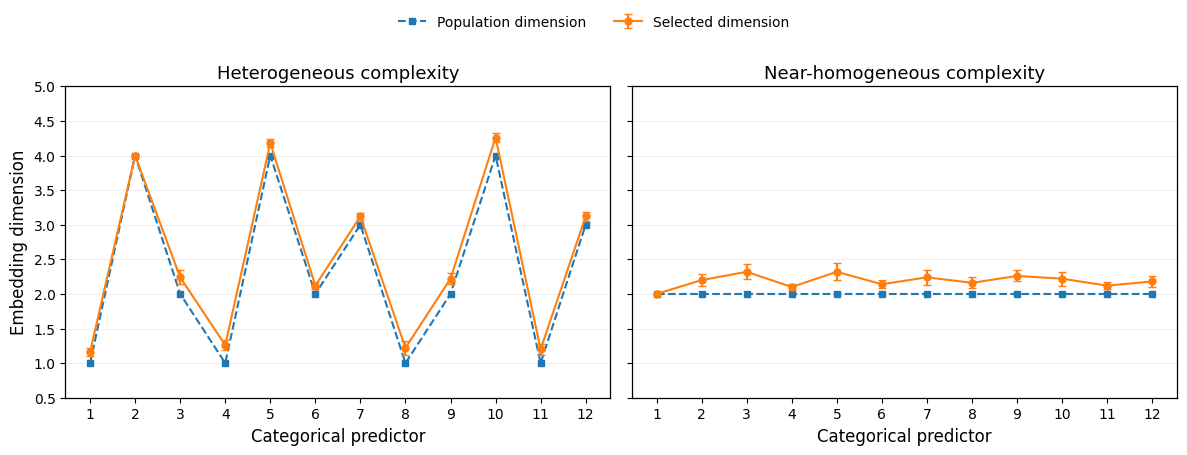

In [7]:
# ============================================================
# FIGURE — POPULATION VS SELECTED DIMENSIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

n_rep = 50

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    sharey=True
)

plot_info = [
    ("heterogeneous", "Heterogeneous complexity"),
    ("near_homogeneous", "Near-homogeneous complexity"),
]

for ax, (regime, title) in zip(axes, plot_info):

    tmp = (
        dimension_summary[
            dimension_summary["regime"] == regime
        ]
        .sort_values("predictor")
        .copy()
    )

    x = tmp["predictor"].to_numpy()

    population = tmp[
        "population_rank"
    ].to_numpy()

    selected = tmp[
        "mean_selected_dimension"
    ].to_numpy()

    mcse = (
        tmp["sd_selected_dimension"].to_numpy()
        / np.sqrt(n_rep)
    )

    # Population dimensions
    ax.plot(
        x,
        population,
        marker="s",
        linestyle="--",
        linewidth=1.5,
        markersize=5,
        label="Population dimension"
    )

    # Monte Carlo mean selected dimensions + 1 MCSE
    ax.errorbar(
        x,
        selected,
        yerr=mcse,
        marker="o",
        linestyle="-",
        linewidth=1.5,
        markersize=5,
        capsize=3,
        label="Selected dimension"
    )

    ax.set_title(title)
    ax.set_xlabel("Categorical predictor")
    ax.set_xticks(x)
    ax.set_ylim(0.5, 5.0)
    ax.grid(
        axis="y",
        alpha=0.20
    )

axes[0].set_ylabel("Embedding dimension")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    "sim2_dimension_allocation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()